In [1]:
import pandas as pd

df = pd.read_csv("service_call_edge_minute.csv")

print(df.head())

   timestamp_bucket_s   caller_service         callee_service  error_count  \
0          1777259940      cartservice              adservice            0   
1          1777259940  checkoutservice            cartservice            0   
2          1777259940  checkoutservice           emailservice            0   
3          1777259940  checkoutservice         paymentservice            0   
4          1777259940  checkoutservice  productcatalogservice            0   

   call_count  latency_mean_ms  latency_p95_ms  latency_max_ms  \
0           1         1.591000          1.5910           1.591   
1          10         4.280900          4.7157           4.740   
2           5         4.659000          5.7654           6.008   
3           5         4.557000          5.4932           5.588   
4           9         2.054778          2.7462           3.199   

   timestamp_bucket_utc                    run_id  \
0  2026-04-27T03:19:00Z  clarknet-20260427_111536   
1  2026-04-27T03:19:00Z  cla

In [2]:
services = set(df["caller_service"]) | set(df["callee_service"])

print("Total services:", len(services))
print(services)
edges = df[["caller_service", "callee_service"]].drop_duplicates()

print("Total unique dependencies:", len(edges))
print(edges)


Total services: 10
{'recommendationservice', 'frontend', 'adservice', 'productcatalogservice', 'shippingservice', 'checkoutservice', 'emailservice', 'cartservice', 'paymentservice', 'currencyservice'}
Total unique dependencies: 82
        caller_service         callee_service
0          cartservice              adservice
1      checkoutservice            cartservice
2      checkoutservice           emailservice
3      checkoutservice         paymentservice
4      checkoutservice  productcatalogservice
...                ...                    ...
30421     emailservice               frontend
34562  currencyservice           emailservice
34604   paymentservice           emailservice
58012     emailservice        currencyservice
59488  currencyservice         paymentservice

[82 rows x 2 columns]


In [3]:
import networkx as nx

G = nx.DiGraph()

G.add_nodes_from(services)

for _, row in edges.iterrows():
    G.add_edge(row["caller_service"], row["callee_service"])

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 10
Edges: 82


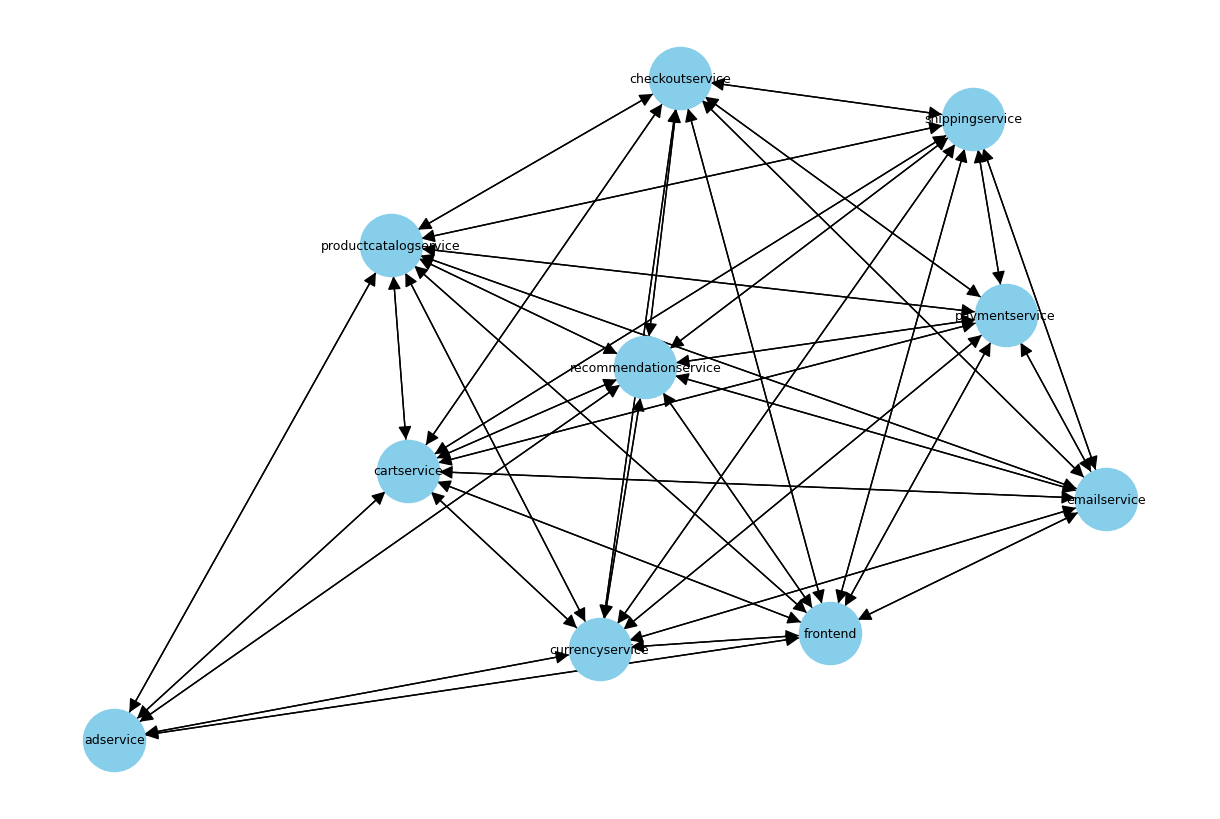

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos,
    with_labels=True,
    node_color='skyblue',
    node_size=2000,
    arrows=True,
    arrowsize=20,
    font_size=9
)

plt.show()

In [6]:
# Number of incoming and outgoing dependencies
for service in G.nodes():
    print(
        service,
        "In-degree:", G.in_degree(service),
        "Out-degree:", G.out_degree(service)
    )

recommendationservice In-degree: 9 Out-degree: 9
frontend In-degree: 9 Out-degree: 9
adservice In-degree: 5 Out-degree: 5
productcatalogservice In-degree: 9 Out-degree: 9
shippingservice In-degree: 8 Out-degree: 8
checkoutservice In-degree: 8 Out-degree: 8
emailservice In-degree: 8 Out-degree: 8
cartservice In-degree: 9 Out-degree: 9
paymentservice In-degree: 8 Out-degree: 8
currencyservice In-degree: 9 Out-degree: 9


In [7]:
in_degree = dict(G.in_degree())

ranking = sorted(
    in_degree.items(),
    key=lambda x: x[1],
    reverse=True
)

for service, degree in ranking:
    print(service, degree)

recommendationservice 9
frontend 9
productcatalogservice 9
cartservice 9
currencyservice 9
shippingservice 8
checkoutservice 8
emailservice 8
paymentservice 8
adservice 5


In [8]:

print("Self loops:", nx.number_of_selfloops(G))

print("Is directed:", G.is_directed())

print("Total edges:", G.number_of_edges())

print("Reciprocal edges:", sum(
    1 for u, v in G.edges() if G.has_edge(v, u)
) // 2)


Self loops: 0
Is directed: True
Total edges: 82
Reciprocal edges: 41


In [9]:
print(edges.head(20))

            caller_service         callee_service
0              cartservice              adservice
1          checkoutservice            cartservice
2          checkoutservice           emailservice
3          checkoutservice         paymentservice
4          checkoutservice  productcatalogservice
5          checkoutservice        shippingservice
6                 frontend              adservice
7                 frontend            cartservice
8                 frontend        checkoutservice
9                 frontend        currencyservice
10                frontend  productcatalogservice
11                frontend  recommendationservice
12                frontend        shippingservice
13   recommendationservice               frontend
14   recommendationservice  productcatalogservice
61             cartservice               frontend
67         currencyservice  productcatalogservice
322  recommendationservice            cartservice
323  recommendationservice        currencyservice


In [10]:
#weightes graph construction
G_weighted = nx.DiGraph()

grouped_edges = df.groupby(
    ['caller_service', 'callee_service']
)['call_count'].sum().reset_index()

for _, row in grouped_edges.iterrows():
    G_weighted.add_edge(
        row['caller_service'],
        row['callee_service'],
        weight=row['call_count']
    )

In [11]:
weighted_in_degree = dict(
    G_weighted.in_degree(weight='weight')
)

ranking = sorted(
    weighted_in_degree.items(),
    key=lambda x: x[1],
    reverse=True
)

for service, calls in ranking:
    print(service, calls)

productcatalogservice 7247745
currencyservice 6010119
cartservice 1471658
recommendationservice 863756
adservice 664846
shippingservice 575559
checkoutservice 57738
emailservice 57567
paymentservice 57564
frontend 4963


In [12]:
for service in G.nodes():

    dependents = nx.ancestors(G, service)

    print(service, len(dependents))

recommendationservice 9
frontend 9
adservice 9
productcatalogservice 9
shippingservice 9
checkoutservice 9
emailservice 9
cartservice 9
paymentservice 9
currencyservice 9


In [14]:
#betweenness centrality
#High betweenness score: Service bahut se shortest paths ke beech mein aati hai.
#Low betweenness score: Service comparatively kam shortest paths ke beech mein aati hai.
betweenness = nx.betweenness_centrality(G)

ranking = sorted(
    betweenness.items(),
    key=lambda x: x[1],
    reverse=True
)

for service, score in ranking:
    print(service, score)

recommendationservice 0.02222222222222222
frontend 0.02222222222222222
productcatalogservice 0.02222222222222222
cartservice 0.02222222222222222
currencyservice 0.02222222222222222
adservice 0.0
shippingservice 0.0
checkoutservice 0.0
emailservice 0.0
paymentservice 0.0


In [15]:
##closeness centrality
closeness = nx.closeness_centrality(G)

for service, score in sorted(
    closeness.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(service, score)

recommendationservice 1.0
frontend 1.0
productcatalogservice 1.0
cartservice 1.0
currencyservice 1.0
shippingservice 0.9
checkoutservice 0.9
emailservice 0.9
paymentservice 0.9
adservice 0.6923076923076923


In [16]:
## page ranking
pagerank = nx.pagerank(G)

for service, score in sorted(
    pagerank.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(service, score)

recommendationservice 0.108785664054785
frontend 0.108785664054785
productcatalogservice 0.108785664054785
cartservice 0.10878566405478499
currencyservice 0.10878566405478499
shippingservice 0.09742521281701927
checkoutservice 0.09742521281701927
emailservice 0.09742521281701927
paymentservice 0.09742521281701927
adservice 0.0663708284579978


In [17]:
##strongly connected components
components = list(nx.strongly_connected_components(G))

for component in components:
    print(component)

{'recommendationservice', 'cartservice', 'frontend', 'adservice', 'productcatalogservice', 'paymentservice', 'shippingservice', 'checkoutservice', 'currencyservice', 'emailservice'}


In [18]:
## checking time range of data set
df['timestamp_bucket_utc'] = pd.to_datetime(
    df['timestamp_bucket_utc']
)

print("Start:", df['timestamp_bucket_utc'].min())
print("End:", df['timestamp_bucket_utc'].max())

print("Unique timestamps:",
      df['timestamp_bucket_utc'].nunique())

Start: 2026-04-27 03:19:00+00:00
End: 2026-05-07 03:17:00+00:00
Unique timestamps: 14146


In [19]:
df['hour'] = df['timestamp_bucket_utc'].dt.floor('h')

hourly_graphs = {}

for hour, group in df.groupby('hour'):

    G_hour = nx.DiGraph()

    edges = group.groupby(
        ['caller_service', 'callee_service']
    )['call_count'].sum().reset_index()

    for _, row in edges.iterrows():
        G_hour.add_edge(
            row['caller_service'],
            row['callee_service'],
            weight=row['call_count']
        )

    hourly_graphs[hour] = G_hour

print("Total hourly graphs:", len(hourly_graphs))

Total hourly graphs: 240


In [20]:
for hour, graph in list(hourly_graphs.items())[:5]:

    print(
        hour,
        "Nodes:", graph.number_of_nodes(),
        "Edges:", graph.number_of_edges(),
        "SCCs:", nx.number_strongly_connected_components(graph)
    )

2026-04-27 03:00:00+00:00 Nodes: 10 Edges: 21 SCCs: 5
2026-04-27 04:00:00+00:00 Nodes: 10 Edges: 30 SCCs: 3
2026-04-27 05:00:00+00:00 Nodes: 10 Edges: 35 SCCs: 2
2026-04-27 06:00:00+00:00 Nodes: 10 Edges: 14 SCCs: 8
2026-04-27 07:00:00+00:00 Nodes: 10 Edges: 19 SCCs: 8


In [22]:
## runtime dependency is changing wrt time

In [23]:
hourly_summary = []

for hour, graph in hourly_graphs.items():
    hourly_summary.append({
        "hour": hour,
        "nodes": graph.number_of_nodes(),
        "edges": graph.number_of_edges(),
        "scc_count": nx.number_strongly_connected_components(graph),
        "largest_scc": max(
            len(c) for c in nx.strongly_connected_components(graph)
        )
    })

summary_df = pd.DataFrame(hourly_summary)

print(summary_df.describe())

       nodes       edges   scc_count  largest_scc
count  240.0  240.000000  240.000000   240.000000
mean    10.0   29.770833    3.966667     7.029167
std      0.0    8.374697    1.775865     1.781819
min     10.0   13.000000    1.000000     1.000000
25%     10.0   24.000000    3.000000     6.000000
50%     10.0   29.000000    4.000000     7.000000
75%     10.0   35.000000    5.000000     8.000000
max     10.0   53.000000   10.000000    10.000000


In [24]:
#Har hour mein har service ka weighted in-degree calculate karte hain:

In [25]:
hourly_centrality = []

for hour, graph in hourly_graphs.items():
    for service in graph.nodes():
        hourly_centrality.append({
            "hour": hour,
            "service": service,
            "in_degree": graph.in_degree(service),
            "out_degree": graph.out_degree(service)
        })

centrality_df = pd.DataFrame(hourly_centrality)

In [26]:
centrality_df.groupby("service")["in_degree"].agg(
    ["mean", "std", "min", "max"]
).sort_values("mean", ascending=False)

,mean,std,min,max
service,,,,
productcatalogservice,5.016667,1.171369,3,9
cartservice,4.220833,1.246410,2,7
frontend,3.808333,1.763393,0,9
shippingservice,3.512500,1.192660,2,7
currencyservice,3.512500,1.381229,1,7
recommendationservice,3.066667,1.291966,1,6
adservice,2.254167,1.017619,1,5
checkoutservice,1.554167,0.851521,1,4
paymentservice,1.433333,0.693464,1,4


In [27]:
## weighted in-degree
  ## btata h ki total kitne calls ek service ko receive hue hain. Agar weighted in-degree high hai, iska matlab hai ki service bahut saare calls receive kar rahi hai aur shayad wo ek critical service ho sakti hai. Agar weighted in-degree low hai, iska matlab hai ki service comparatively kam calls receive kar rahi hai aur shayad wo ek less critical service ho sakti hai.

In [28]:
weighted_hourly = []

for hour, group in df.groupby('hour'):
    incoming = group.groupby('callee_service')['call_count'].sum()

    for service, calls in incoming.items():
        weighted_hourly.append({
            "hour": hour,
            "service": service,
            "incoming_calls": calls
        })

weighted_df = pd.DataFrame(weighted_hourly)

In [29]:
weighted_df.groupby("service")["incoming_calls"].agg(
    ["mean", "std", "min", "max"]
).sort_values("mean", ascending=False)

,mean,std,min,max
service,,,,
productcatalogservice,30198.937500,11221.249570,7677,52752
currencyservice,25042.162500,9222.379532,6369,43283
cartservice,6131.908333,2254.986393,1567,10618
recommendationservice,3598.983333,1329.596299,919,6266
adservice,2770.191667,1008.272073,724,4768
shippingservice,2398.162500,890.826236,612,4253
checkoutservice,240.575000,92.080614,70,436
emailservice,239.862500,91.548109,70,439
paymentservice,239.850000,91.623310,70,436


In [30]:
weighted_df.groupby("service")["incoming_calls"].agg(
    total="sum",
    mean="mean",
    median="median",
    std="std"
).sort_values("mean", ascending=False)

,total,mean,median,std
service,,,,
productcatalogservice,7247745,30198.937500,30261.0,11221.249570
currencyservice,6010119,25042.162500,25235.5,9222.379532
cartservice,1471658,6131.908333,6189.0,2254.986393
recommendationservice,863756,3598.983333,3626.0,1329.596299
adservice,664846,2770.191667,2799.5,1008.272073
shippingservice,575559,2398.162500,2403.0,890.826236
checkoutservice,57738,240.575000,234.5,92.080614
emailservice,57567,239.862500,235.0,91.548109
paymentservice,57564,239.850000,234.5,91.623310


In [31]:
all_hours = sorted(df['hour'].unique())
all_services = sorted(services)

complete_index = pd.MultiIndex.from_product(
    [all_hours, all_services],
    names=['hour', 'service']
)

complete_df = (
    weighted_df
    .set_index(['hour', 'service'])
    .reindex(complete_index, fill_value=0)
    .reset_index()
)

final_summary = complete_df.groupby('service')['incoming_calls'].agg(
    total='sum',
    mean='mean',
    median='median',
    std='std'
).sort_values('mean', ascending=False)

print(final_summary)

                         total          mean   median           std
service                                                            
productcatalogservice  7247745  30198.937500  30261.0  11221.249570
currencyservice        6010119  25042.162500  25235.5   9222.379532
cartservice            1471658   6131.908333   6189.0   2254.986393
recommendationservice   863756   3598.983333   3626.0   1329.596299
adservice               664846   2770.191667   2799.5   1008.272073
shippingservice         575559   2398.162500   2403.0    890.826236
checkoutservice          57738    240.575000    234.5     92.080614
emailservice             57567    239.862500    235.0     91.548109
paymentservice           57564    239.850000    234.5     91.623310
frontend                  4963     20.679167     18.0     15.994285


In [32]:
## hourly ranking consistency


In [33]:
complete_df['rank'] = (
    complete_df.groupby('hour')['incoming_calls']
    .rank(method='min', ascending=False)
)

rank_summary = complete_df.groupby('service').agg(
    avg_rank=('rank', 'mean'),
    top_2_hours=('rank', lambda x: (x <= 2).sum()),
    top_3_hours=('rank', lambda x: (x <= 3).sum())
).sort_values('avg_rank')

print(rank_summary)

                        avg_rank  top_2_hours  top_3_hours
service                                                   
productcatalogservice   1.000000          240          240
currencyservice         2.000000          240          240
cartservice             3.000000            0          240
recommendationservice   4.000000            0            0
adservice               5.000000            0            0
shippingservice         6.000000            0            0
checkoutservice         7.237500            0            0
emailservice            7.320833            0            0
paymentservice          7.341667            0            0
frontend               10.000000            0            0


In [34]:
exposure = []

for service in G.nodes():
    direct = list(G.predecessors(service))
    transitive = list(nx.ancestors(G, service))

    exposure.append({
        "service": service,
        "direct_dependents": len(direct),
        "transitive_dependents": len(transitive)
    })

exposure_df = pd.DataFrame(exposure)

print(
    exposure_df.sort_values(
        "direct_dependents",
        ascending=False
    )
)

                 service  direct_dependents  transitive_dependents
0  recommendationservice                  9                      9
1               frontend                  9                      9
3  productcatalogservice                  9                      9
7            cartservice                  9                      9
9        currencyservice                  9                      9
4        shippingservice                  8                      9
6           emailservice                  8                      9
5        checkoutservice                  8                      9
8         paymentservice                  8                      9
2              adservice                  5                      9


In [35]:
#hourly dependency exposure analysis

In [36]:
hourly_exposure = []

for hour, graph in hourly_graphs.items():

    for service in graph.nodes():

        direct = len(list(graph.predecessors(service)))
        transitive = len(nx.ancestors(graph, service))

        hourly_exposure.append({
            "hour": hour,
            "service": service,
            "direct_dependents": direct,
            "transitive_dependents": transitive
        })

hourly_exposure_df = pd.DataFrame(hourly_exposure)

In [37]:
exposure_summary = hourly_exposure_df.groupby("service").agg(
    mean_direct=("direct_dependents", "mean"),
    std_direct=("direct_dependents", "std"),
    mean_transitive=("transitive_dependents", "mean"),
    std_transitive=("transitive_dependents", "std")
).sort_values("mean_direct", ascending=False)

print(exposure_summary)

                       mean_direct  std_direct  mean_transitive  \
service                                                           
productcatalogservice     5.016667    1.171369         6.345833   
cartservice               4.220833    1.246410         6.291667   
frontend                  3.808333    1.763393         6.029167   
shippingservice           3.512500    1.192660         6.379167   
currencyservice           3.512500    1.381229         6.162500   
recommendationservice     3.066667    1.291966         6.125000   
adservice                 2.254167    1.017619         6.425000   
checkoutservice           1.554167    0.851521         6.075000   
paymentservice            1.433333    0.693464         6.933333   
emailservice              1.391667    0.669676         6.937500   

                       std_transitive  
service                                
productcatalogservice        1.300621  
cartservice                  1.457319  
frontend                     1.7818

In [38]:
#event horizon candidate indentifiaction


In [39]:
candidate_magnets = [
    "productcatalogservice",
    "currencyservice",
    "cartservice"
]

non_magnets = [
    s for s in G.nodes()
    if s not in candidate_magnets
]

path_participation = {s: set() for s in non_magnets}

for source in non_magnets:
    for target in candidate_magnets:

        if nx.has_path(G, source, target):

            paths = list(nx.all_shortest_paths(
                G, source, target
            ))

            for path in paths:
                for node in path[1:-1]:

                    if node in path_participation:
                        path_participation[node].add(
                            (source, target)
                        )

results = pd.DataFrame([
    {
        "service": service,
        "path_pairs": len(pairs)
    }
    for service, pairs in path_participation.items()
])

results = results.sort_values(
    "path_pairs", ascending=False
)

print(results)

                 service  path_pairs
0  recommendationservice           0
1               frontend           0
2              adservice           0
3        shippingservice           0
4        checkoutservice           0
5           emailservice           0
6         paymentservice           0


In [41]:
##hourly
hourly_path_results = []

for hour, graph in hourly_graphs.items():

    for source in non_magnets:
        for target in candidate_magnets:

            if source == target:
                continue

            if nx.has_path(graph, source, target):

                paths = nx.all_shortest_paths(
                    graph, source, target
                )

                for path in paths:
                    for node in path[1:-1]:

                        hourly_path_results.append({
                            "hour": hour,
                            "source": source,
                            "target": target,
                            "intermediary": node
                        })

hourly_paths_df = pd.DataFrame(hourly_path_results)

print(hourly_paths_df.head(20))
print("Total intermediary appearances:",
      len(hourly_paths_df))

                        hour                 source                 target  \
0  2026-04-27 03:00:00+00:00              adservice  productcatalogservice   
1  2026-04-27 03:00:00+00:00              adservice        currencyservice   
2  2026-04-27 03:00:00+00:00              adservice            cartservice   
3  2026-04-27 03:00:00+00:00        shippingservice  productcatalogservice   
4  2026-04-27 03:00:00+00:00        shippingservice        currencyservice   
5  2026-04-27 03:00:00+00:00        shippingservice            cartservice   
6  2026-04-27 03:00:00+00:00        checkoutservice        currencyservice   
7  2026-04-27 03:00:00+00:00        checkoutservice        currencyservice   
8  2026-04-27 03:00:00+00:00        checkoutservice        currencyservice   
9  2026-04-27 03:00:00+00:00        checkoutservice        currencyservice   
10 2026-04-27 04:00:00+00:00              adservice  productcatalogservice   
11 2026-04-27 04:00:00+00:00              adservice        curre

In [42]:
unique_paths = hourly_paths_df.drop_duplicates(
    subset=["hour", "source", "target", "intermediary"]
)

intermediary_summary = unique_paths.groupby(
    "intermediary"
).agg(
    path_pairs=("source", "count"),
    active_hours=("hour", "nunique")
).sort_values(
    "path_pairs", ascending=False
)

print(intermediary_summary)

                       path_pairs  active_hours
intermediary                                   
frontend                      575           179
productcatalogservice         553           191
cartservice                   216           132
currencyservice               197           109
recommendationservice         154            68
shippingservice               122            79
checkoutservice                95            41
paymentservice                 15             8
adservice                      10             8
emailservice                   10             6


In [43]:
candidate_magnets = {
    "productcatalogservice",
    "currencyservice",
    "cartservice"
}

eh_candidates = {
    "frontend",
    "recommendationservice",
    "shippingservice",
    "checkoutservice",
    "paymentservice",
    "emailservice",
    "adservice"
}

for service in eh_candidates:
    print(service, intermediary_summary.loc[service].to_dict())

recommendationservice {'path_pairs': 154, 'active_hours': 68}
adservice {'path_pairs': 10, 'active_hours': 8}
shippingservice {'path_pairs': 122, 'active_hours': 79}
paymentservice {'path_pairs': 15, 'active_hours': 8}
frontend {'path_pairs': 575, 'active_hours': 179}
emailservice {'path_pairs': 10, 'active_hours': 6}
checkoutservice {'path_pairs': 95, 'active_hours': 41}


In [44]:
##magnet exposure ratio

In [46]:
candidate_magnets = {
    "productcatalogservice",
    "currencyservice",
    "cartservice"
}

magnet_exposure = []

for hour, graph in hourly_graphs.items():

    for service in graph.nodes():

        if service in candidate_magnets:
            continue

        reachable = nx.descendants(graph, service)

        reachable_magnets = (
            reachable & candidate_magnets
        )

        ratio = len(reachable_magnets) / len(candidate_magnets)

        magnet_exposure.append({
            "hour": hour,
            "service": service,
            "reachable_magnets": len(reachable_magnets),
            "exposure_ratio": ratio
        })

magnet_df = pd.DataFrame(magnet_exposure)

In [47]:
magnet_summary = magnet_df.groupby("service").agg(
    mean_exposure=("exposure_ratio", "mean"),
    std_exposure=("exposure_ratio", "std"),
    exposed_hours=("exposure_ratio",
                   lambda x: (x > 0).sum())
).sort_values("mean_exposure", ascending=False)

print(magnet_summary)

                       mean_exposure  std_exposure  exposed_hours
service                                                          
frontend                    1.000000      0.000000            240
checkoutservice             0.986111      0.066748            240
recommendationservice       0.944444      0.184642            240
shippingservice             0.716667      0.449495            173
adservice                   0.627778      0.482484            152
paymentservice              0.144444      0.349625             36
emailservice                0.141667      0.349437             34


In [48]:
threshold_pairs = [(0.4, 0.6), (0.6, 0.8)]

for low, high in threshold_pairs:
    print(f"\nThresholds = ({low}, {high})")

    for service, row in magnet_summary.iterrows():
        score = row["mean_exposure"]

        if score >= high:
            region = "High exposure"
        elif score >= low:
            region = "Medium exposure"
        else:
            region = "Low exposure"

        print(service, ":", region)


Thresholds = (0.4, 0.6)
frontend : High exposure
checkoutservice : High exposure
recommendationservice : High exposure
shippingservice : High exposure
adservice : High exposure
paymentservice : Low exposure
emailservice : Low exposure

Thresholds = (0.6, 0.8)
frontend : High exposure
checkoutservice : High exposure
recommendationservice : High exposure
shippingservice : Medium exposure
adservice : Medium exposure
paymentservice : Low exposure
emailservice : Low exposure
